# **Waze Project: EDA & Visualization**

### **Task 1. Imports and data loading**




In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Load the dataset into a dataframe
df = pd.read_csv('waze_dataset.csv', index_col=0)

### **Task 2. Data exploration and cleaning**

In [3]:
df.head()

,label,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days,device
ID,,,,,,,,,,,,
0,retained,283,226,296.748273,2276,208,0,2628.845068,1985.775061,28,19,Android
1,retained,133,107,326.896596,1225,19,64,13715.920550,3160.472914,13,11,iPhone
2,retained,114,95,135.522926,2651,0,0,3059.148818,1610.735904,14,8,Android
3,retained,49,40,67.589221,15,322,7,913.591123,587.196542,7,3,iPhone
4,retained,84,68,168.247020,1562,166,5,3950.202008,1219.555924,27,18,Android


In [4]:
df.shape

(14999, 12)

Generate summary statistics using the `describe()` method.

In [5]:
df.describe()

,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,80.633776,67.281152,189.964447,1749.837789,121.605974,29.672512,4039.340921,1860.976012,15.537102,12.179879
std,80.699065,65.913872,136.405128,1008.513876,148.121544,45.394651,2502.149334,1446.702288,9.004655,7.824036
min,0.000000,0.000000,0.220211,4.000000,0.000000,0.000000,60.441250,18.282082,0.000000,0.000000
25%,23.000000,20.000000,90.661156,878.000000,9.000000,0.000000,2212.600607,835.996260,8.000000,5.000000
50%,56.000000,48.000000,159.568115,1741.000000,71.000000,9.000000,3493.858085,1478.249859,16.000000,12.000000
75%,112.000000,93.000000,254.192341,2623.500000,178.000000,43.000000,5289.861262,2464.362632,23.000000,19.000000
max,743.000000,596.000000,1216.154633,3500.000000,1236.000000,415.000000,21183.401890,15851.727160,31.000000,30.000000


Generate summary information using the `info()` method.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 14999 entries, 0 to 14998
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   label                    14299 non-null  object 
 1   sessions                 14999 non-null  int64  
 2   drives                   14999 non-null  int64  
 3   total_sessions           14999 non-null  float64
 4   n_days_after_onboarding  14999 non-null  int64  
 5   total_navigations_fav1   14999 non-null  int64  
 6   total_navigations_fav2   14999 non-null  int64  
 7   driven_km_drives         14999 non-null  float64
 8   duration_minutes_drives  14999 non-null  float64
 9   activity_days            14999 non-null  int64  
 10  driving_days             14999 non-null  int64  
 11  device                   14999 non-null  object 
dtypes: float64(3), int64(7), object(2)
memory usage: 1.5+ MB


Check null values using the `isnull()` method.

In [7]:
df.isnull().sum()

label                      700
sessions                     0
drives                       0
total_sessions               0
n_days_after_onboarding      0
total_navigations_fav1       0
total_navigations_fav2       0
driven_km_drives             0
duration_minutes_drives      0
activity_days                0
driving_days                 0
device                       0
dtype: int64

In [8]:
df[df.isnull().any(axis=1)]

,label,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days,device
ID,,,,,,,,,,,,
77,NaN,63,50,133.104155,783,201,0,2649.015822,1517.209970,19,13,iPhone
80,NaN,116,93,436.060183,1584,283,62,4183.409514,3121.889952,18,15,iPhone
98,NaN,78,64,583.492789,3414,0,0,1811.140893,642.189122,12,11,Android
111,NaN,106,102,113.379056,2228,14,0,2817.481840,2011.724274,17,13,Android
142,NaN,32,26,222.129310,208,55,10,2459.816477,874.427617,11,7,iPhone
...,...,...,...,...,...,...,...,...,...,...,...,...
14941,NaN,191,160,485.328204,1287,25,0,6468.181924,3466.104564,14,14,iPhone
14943,NaN,48,38,96.797017,555,0,6,8266.129497,5902.351711,19,19,iPhone
14945,NaN,34,29,134.416604,1643,268,2,4554.007843,1579.211201,18,17,Android


### **Task 3a. Visualizations**

Select data visualization types that will help you understand and explain the data.

Now that you know which data columns you’ll use, it is time to decide which data visualization makes the most sense for EDA of the Waze dataset.

**Question:** What type of data visualization(s) will be most helpful?

* Line graph
* Bar chart
* Box plot
* Histogram
* Heat map
* Scatter plot
* A geographic map



#### **`sessions`**

_The number of occurrence of a user opening the app during the month_

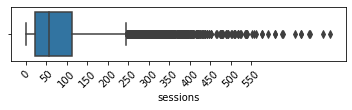

In [9]:
# Box plot
plt.figure(figsize=(6,1))
sns.boxplot(x=df['sessions'])
plt.xticks(range(0,600,50), rotation=45)
plt.show()

In [10]:
median = df['sessions'].median()
median

56.0

In [11]:
# build a def for drawing histogram

def histogram_func(col, median_text=True, **kwarg):
    plt.figure(figsize=(5,3))
    ax = sns.histplot(data=df, x=col, **kwarg)
    
    col_median = round(df[col].median(),1)
    plt.axvline(col_median, color='red', linestyle='--')
    if median_text:
        ax.text(0.25,0.85,f'median={col_median}', color='red',
               ha='left', va = 'top', transform=ax.transAxes)
    else:
        print('Median: ',col_median)
    plt.title(f'{col} histogram');
    

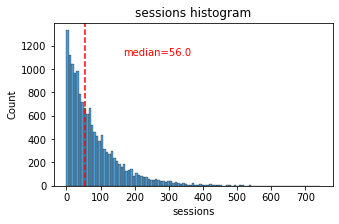

In [12]:
# Histogram
histogram_func('sessions', median_text=True)

The `sessions` variable is a right-skewed distribution with half of the observations having 56 or fewer sessions. However, as indicated by the boxplot, some users have more than 700.

#### **`drives`**

_An occurrence of driving at least 1 km during the month_

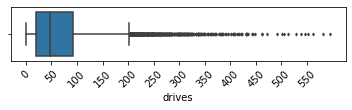

In [13]:
# Box plot
plt.figure(figsize=(6,1))
sns.boxplot(data=df, x='drives', fliersize=2)
plt.xticks(range(0,600,50), rotation=45)
plt.show()

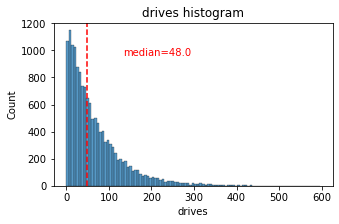

In [14]:
# Histogram
histogram_func('drives', median_text=True)

The `drives` information follows a distribution similar to the `sessions` variable. It is right-skewed, approximately log-normal, with a median of 48. However, some drivers had over 400 drives in the last month.

#### **`total_sessions`**

_A model estimate of the total number of sessions since a user has onboarded_

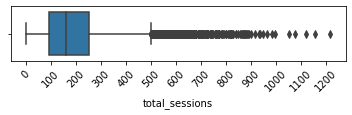

In [15]:
# Box plot
plt.figure(figsize=(6,1))
sns.boxplot(data=df, x='total_sessions')
plt.xticks(range(0,1300,100), rotation=45)
plt.show()


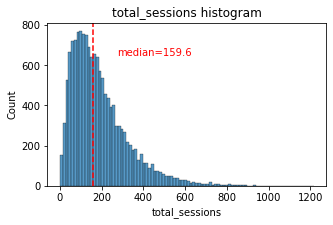

In [16]:
# Histogram
histogram_func('total_sessions', median_text=True)

The `total_sessions` is a right-skewed distribution. The median total number of sessions is 159.6. This is interesting information because, if the median number of sessions in the last month was 48 and the median total sessions was ~160, then it seems that a large proportion of a user's total drives might have taken place in the last month. This is something you can examine more closely later.

#### **`n_days_after_onboarding`**

_The number of days since a user signed up for the app_

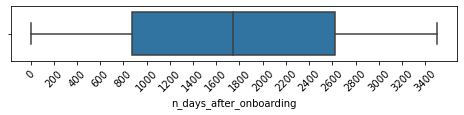

In [17]:
# Box plot
plt.figure(figsize=(8,1))
sns.boxplot(data=df, x='n_days_after_onboarding')
plt.xticks(range(0,3600,200), rotation=45)
plt.show()

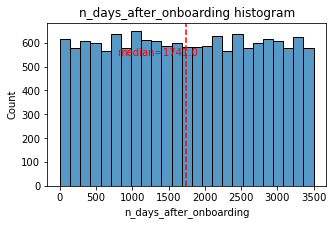

In [18]:
# Histogram
histogram_func('n_days_after_onboarding', median_text=True)

The total user tenure (i.e., number of days since
onboarding) is a uniform distribution with values ranging from near-zero to \~3,500 (\~9.5 years).

#### **`driven_km_drives`**

_Total kilometers driven during the month_

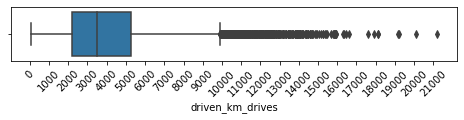

In [19]:
# Box plot
plt.figure(figsize=(8,1))
sns.boxplot(data=df, x='driven_km_drives')
plt.xticks(range(0,22000,1000), rotation=45)
plt.show()

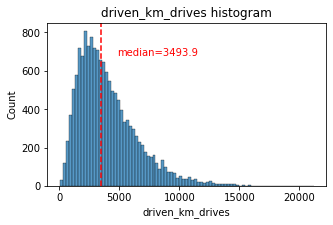

In [20]:
# Histogram
histogram_func('driven_km_drives', median_text=True)

The number of drives driven in the last month per user is a right-skewed distribution with half the users driving under 3,495 kilometers. As you discovered in the analysis from the previous course, the users in this dataset drive _a lot_. The longest distance driven in the month was over half the circumferene of the earth.

#### **`duration_minutes_drives`**

_Total duration driven in minutes during the month_

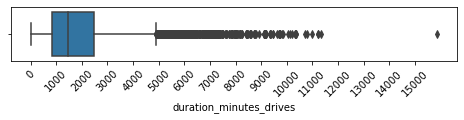

In [21]:
# Box plot
plt.figure(figsize=(8,1))
sns.boxplot(data=df, x='duration_minutes_drives')
plt.xticks(range(0,16000,1000), rotation=45)
plt.show()

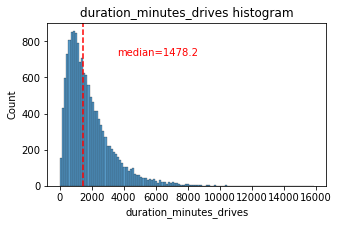

In [22]:
# Histogram
histogram_func('duration_minutes_drives', median_text=True)

The `duration_minutes_drives` variable has a heavily skewed right tail. Half of the users drove less than \~1,478 minutes (\~25 hours), but some users clocked over 250 hours over the month.

#### **`activity_days`**

_Number of days the user opens the app during the month_

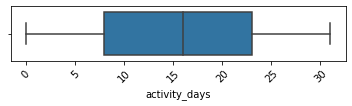

In [23]:
# Box plot
plt.figure(figsize=(6,1))
sns.boxplot(data=df, x='activity_days')
plt.xticks(range(0,35,5), rotation=45)
plt.show()

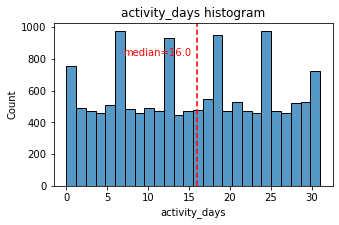

In [24]:
# Histogram
histogram_func('activity_days', median_text=True)

Within the last month, users opened the app a median of 16 times. The box plot reveals a centered distribution. The histogram shows a nearly uniform distribution of ~500 people opening the app on each count of days. However, there are ~250 people who didn't open the app at all and ~250 people who opened the app every day of the month.

This distribution is noteworthy because it does not mirror the `sessions` distribution, which you might think would be closely correlated with `activity_days`.

#### **`driving_days`**

_Number of days the user drives (at least 1 km) during the month_

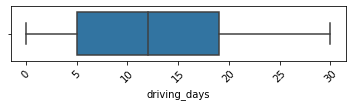

In [25]:
# Box plot
plt.figure(figsize=(6,1))
sns.boxplot(data=df, x='driving_days')
plt.xticks(range(0,35,5), rotation=45)
plt.show()

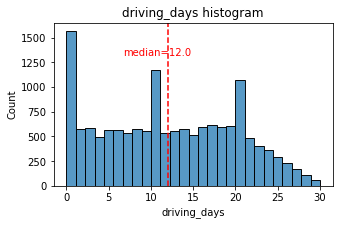

In [26]:
# Histogram
histogram_func('driving_days', median_text=True)

The number of days users drove each month is almost uniform, and it largely correlates with the number of days they opened the app that month, except the `driving_days` distribution tails off on the right.

However, there were almost twice as many users (\~1,000 vs. \~550) who did not drive at all during the month. This might seem counterintuitive when considered together with the information from `activity_days`. That variable had \~500 users opening the app on each of most of the day counts, but there were only \~250 users who did not open the app at all during the month and ~250 users who opened the app every day. Flag this for further investigation later.

#### **`device`**

_The type of device a user starts a session with_

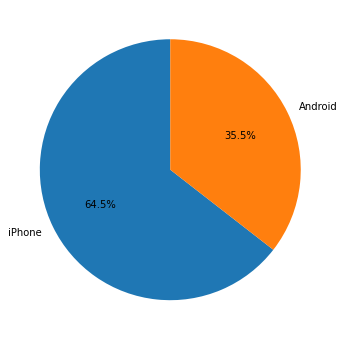

In [27]:
# Pie chart
plt.figure(figsize=(6,6))
plt.pie(x= df['device'].value_counts(), labels=['iPhone', 'Android'],
       autopct = '%.1f%%',
       startangle=90)
plt.show()

In [28]:
df['device'].value_counts()

iPhone     9672
Android    5327
Name: device, dtype: int64

There are nearly twice as many iPhone users as Android users represented in this data.

#### **`label`**

_Binary target variable (“retained” vs “churned”) for if a user has churned anytime during the course of the month_

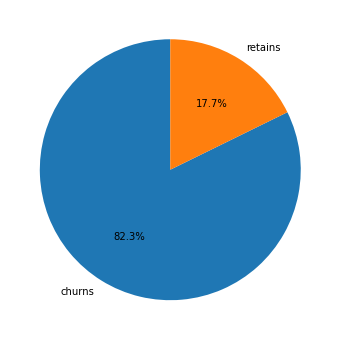

In [29]:
# Pie chart
plt.figure(figsize=(6,6))
plt.pie(x= df['label'].value_counts(), labels=['churns', 'retains'],
       autopct = '%.1f%%',
       startangle=90)
plt.show()

Less than 18% of the users churned.

#### **`driving_days` vs. `activity_days`**

Because both `driving_days` and `activity_days` represent counts of days over a month and they're also closely related, plot them together on a single histogram. This will help to better understand how they relate to each other without having to scroll back and forth comparing histograms in two different places.

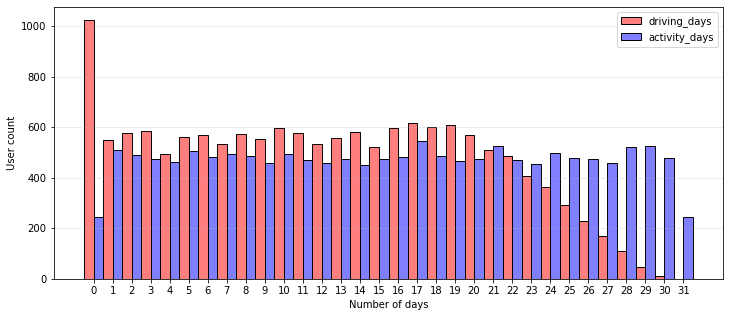

In [30]:
# Histogram
plt.figure(figsize=(12,5))
sns.histplot(data=df[['driving_days','activity_days']], bins=range(0,32),
            multiple='dodge', alpha=0.5,
            palette={'driving_days':'red','activity_days':'blue'},
            discrete=True,
            legend=True)
plt.xticks(range(0,32))
plt.xlabel('Number of days')
plt.ylabel('User count')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [31]:
print(f"Max of driving days: {df['driving_days'].max()} days")
print(f"Max of activity days: {df['activity_days'].max()} days")

Max of driving days: 30 days
Max of activity days: 31 days


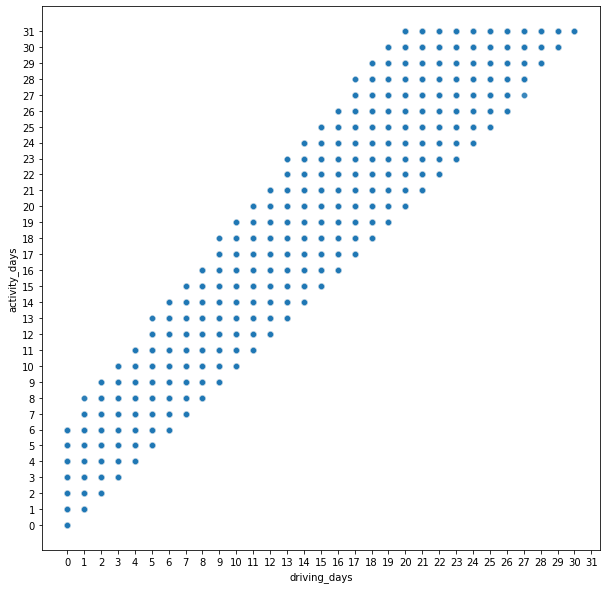

In [32]:
# Scatter plot
plt.figure(figsize=(10,10))
sns.scatterplot(data=df, x='driving_days', y='activity_days',
               alpha=0.5, legend=True,
               x_bins=range(0,32),
               y_bins=range(0,32))
plt.xticks(range(0,32))
plt.yticks(range(0,32))
plt.show()

Notice that there is a theoretical limit, and none of the samples in this data violate this rule, which is good.

#### **Retention by device**

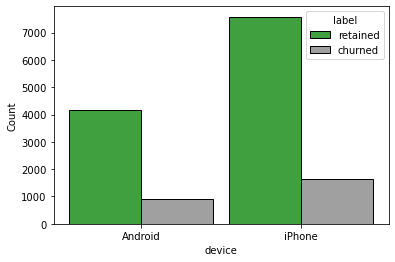

In [33]:
# Histogram
sns.histplot(x=df['device'], hue=df['label'],
            palette={'retained':'green','churned':'grey'},
            multiple='dodge',
            hue_order=['retained','churned'],
            shrink=0.9)
plt.show()

The proportion of churned users to retained users is consistent between device types.

#### **Retention by kilometers driven per driving day**

In [34]:
# 1. Create `km_per_driving_day` column
df['km_per_driving_day'] = df['driven_km_drives'] / df['driving_days']

# 2. Call `describe()` on the new column
df['km_per_driving_day'].describe().reset_index()

,index,km_per_driving_day
0,count,1.499900e+04
1,mean,inf
2,std,NaN
3,min,3.022063e+00
4,25%,1.672804e+02
5,50%,3.231459e+02
6,75%,7.579257e+02
7,max,inf


In [3]:
# Convert infinite values to zero
df['km_per_driving_day'] = df['km_per_driving_day'].replace(np.inf,0)
df['km_per_driving_day'].describe().reset_index()

KeyError: 'km_per_driving_day'

The maximum value is 15,420 kilometers _per drive day_. This is physically impossible. Driving 100 km/hour for 12 hours is 1,200 km. It's unlikely many people averaged more than this each day they drove, so, for now, disregard rows where the distance in this column is greater than 1,200 km.

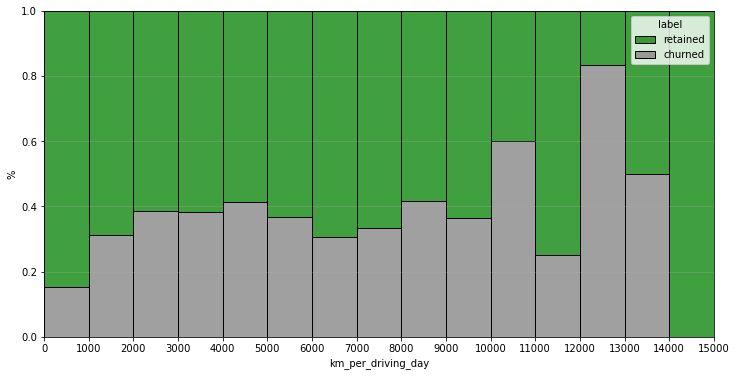

In [37]:
# Histogram
plt.figure(figsize=(12,6))
sns.histplot(data=df, x='km_per_driving_day', hue='label',
            palette={'retained':'green','churned':'grey'},
            multiple='fill',
            bins=range(0,16000,1000),
            legend=True)
plt.xticks(range(0,16000,1000))
plt.ylabel('%')
plt.grid(axis='y',alpha=0.3)
plt.show()

The churn rate tends to increase as the mean daily distance driven increases. It would be worth investigating further the reasons for long-distance users to discontinue using the app.

#### **Churn rate per number of driving days**

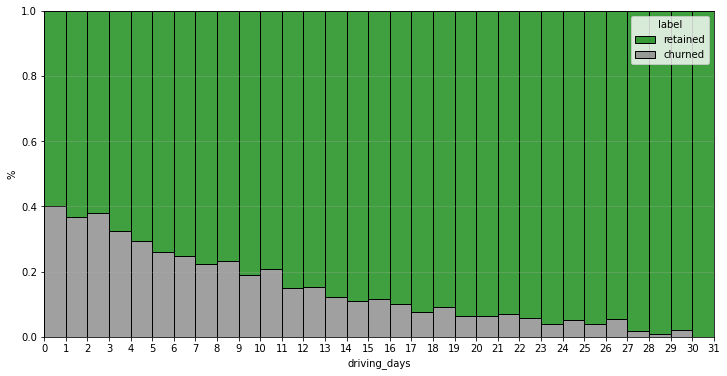

In [38]:
# Histogram
plt.figure(figsize=(12,6))
sns.histplot(data=df, x='driving_days', hue='label',
            palette={'retained':'green','churned':'grey'},
            multiple='fill',
            bins=range(0,32),
            legend=True)
plt.xticks(range(0,32))
plt.grid(axis='y',alpha=0.3)
plt.ylabel('%')
plt.show()

The churn rate is highest for people who didn't use Waze much during the last month. The more times they used the app, the less likely they were to churn. While 40% of the users who didn't use the app at all last month churned, nobody who used the app 30 days churned.

This isn't surprising. If people who used the app a lot churned, it would likely indicate dissatisfaction. When people who don't use the app churn, it might be the result of dissatisfaction in the past, or it might be indicative of a lesser need for a navigational app. Maybe they moved to a city with good public transportation and don't need to drive anymore.

#### **Proportion of sessions that occurred in the last month**

Create a new column `percent_sessions_in_last_month` that represents the percentage of each user's total sessions that were logged in their last month of use.

In [39]:
df['percent_sessions_in_last_month'] = df['sessions'] / df['total_sessions']

What is the median value of the new column?

In [40]:
df['percent_sessions_in_last_month'].median()

0.42309702992763176

Now, create a histogram depicting the distribution of values in this new column.

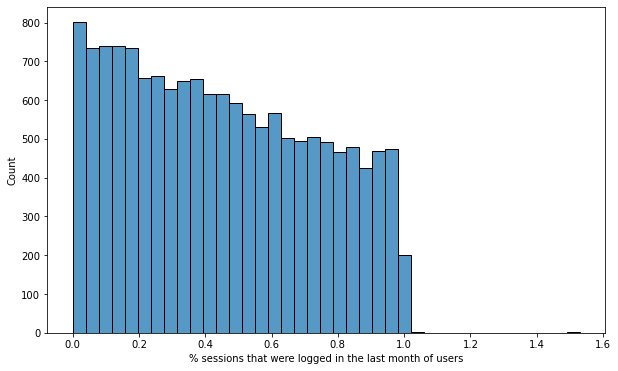

In [41]:
# Histogram
plt.figure(figsize=(10,6))
sns.histplot(x=df['percent_sessions_in_last_month'])
plt.xlabel('% sessions that were logged in the last month of users')
plt.show()

Check the median value of the `n_days_after_onboarding` variable.

In [42]:
df['n_days_after_onboarding'].median()

1741.0

Half of the people in the dataset had 40% or more of their sessions in just the last month, yet the overall median time since onboarding is almost five years.

Make a histogram of `n_days_after_onboarding` for just the people who had 40% or more of their total sessions in the last month.

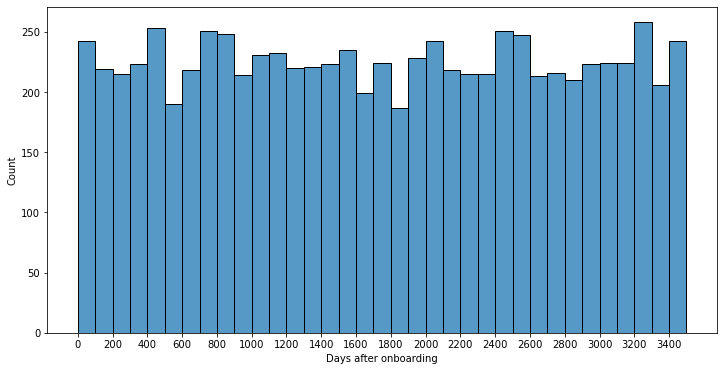

In [43]:
# Histogram
plt.figure(figsize=(12,6))
sns.histplot(x=df[df['percent_sessions_in_last_month'] >= 0.4]['n_days_after_onboarding'],
            bins=range(0,3600,100))
plt.xlabel('Days after onboarding')
plt.xticks(range(0,3600,200))
plt.show()

The number of days since onboarding for users with 40% or more of their total sessions occurring in just the last month is a uniform distribution. This is very strange. It's worth asking Waze why so many long-time users suddenly used the app so much in the last month.

### **Task 3b. Handling outliers**

In [45]:
column_lst = ['sessions','drives','total_sessions','driven_km_drives','duration_minutes_drives']

for col in column_lst:
    q95 = df[col].quantile(0.95)
    df.loc[df[col] > q95, col] = q95
    print(f"Completed impute outliers in {col} column with  the 95th percentile")

Completed impute outliers in sessions column with  the 95th percentile
Completed impute outliers in drives column with  the 95th percentile
Completed impute outliers in total_sessions column with  the 95th percentile
Completed impute outliers in driven_km_drives column with  the 95th percentile
Completed impute outliers in duration_minutes_drives column with  the 95th percentile


In [46]:
df.describe()

,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days,km_per_driving_day,percent_sessions_in_last_month
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,76.568705,64.058204,184.031320,1749.837789,121.605974,29.672512,3939.632764,1789.647426,15.537102,12.179879,578.963113,0.449255
std,67.297958,55.306924,118.600463,1008.513876,148.121544,45.394651,2216.041510,1222.705167,9.004655,7.824036,1030.094384,0.286919
min,0.000000,0.000000,0.220211,4.000000,0.000000,0.000000,60.441250,18.282082,0.000000,0.000000,0.000000,0.000000
25%,23.000000,20.000000,90.661156,878.000000,9.000000,0.000000,2212.600607,835.996260,8.000000,5.000000,136.238895,0.196221
50%,56.000000,48.000000,159.568115,1741.000000,71.000000,9.000000,3493.858085,1478.249859,16.000000,12.000000,272.889272,0.423097
75%,112.000000,93.000000,254.192341,2623.500000,178.000000,43.000000,5289.861262,2464.362632,23.000000,19.000000,558.686918,0.687216
max,243.000000,201.000000,454.363204,3500.000000,1236.000000,415.000000,8889.794236,4668.899349,31.000000,30.000000,15420.234110,1.530637


### **Task 4. Conclusion**

1. Nearly all variables are either sharply right-skewed or uniformly distributed. While the right-skewed distribution indicates most of values concentrate in the lower end, the uniform tells data appears evenly.
2. None is problematic because there is no indication that any variable is completely wrong. However, several variables have extreme outliers that is barely possible such as `driven_km_drives`
3. I want to ask Waze's data team about the recently absnormal usage of users who have registered for many years.
4. 82% users are retained and 18% of them are churned regardless of devices used.
5. Distance driven per driving day had a positive correlation with user churn. The farther a user drove on each driving day, the more likely they were to churn. On the other hand, number of driving days had a negative correlation with churn. Users who drove more days of the last month were less likely to churn.
* Users who tend to drive more in frequency are more likely to retained
* Users who tend to drive longer in their driving days are more likely to churn.
Besides, driving days also has a positive correlation with user churn. The more days they drive, the more possibility they are retained.
6. Users of all tenures from brand new to \~10 years were relatively evenly represented in the data. This is borne out by the histogram for `n_days_after_onboarding`, which reveals a uniform distribution for this variable.
